# NB3 — Fleet index, donor gains, DC/AC priors, drift boundary, and freeze (part 1)

Guide §3.3–§3.6, D02, D10, D21, D28, D30. Reads `results/nb2_panel/`; writes `results/nb3_index/`.

**Rules fixed before any number below (selection uses the 10 validation units only):**
1. *Gain-fit threshold* k_min ∈ {0.3, 0.5, 0.7}: median estimator; choose the lowest median validation nRMSE₀ (same-time reconstruction with the unit's oracle 90-day gain). Ties go to 0.5 (guide default).
2. *Estimator*: the censored Huber index is kept only if its median validation nRMSE₀ is lower than the median index's (guide §3.3); otherwise 'censored' leaves the title.
3. *Prior*: G2 is kept only if its median absolute gain error on the validation units is lower than G1's (guide §3.5). G0 is reported.
4. *Drift boundary* (D10, D30): PELT on the daily log-ratio of measured GHI to the fleet proxy, penalty raised until one change point remains; an event is drifted if at least 45 of its 90 days fall after it.

Then part 1 of the frozen configuration is written, and only then are the indices, gains and priors of the test events computed — from donors and nameplates only. No test target is read in this notebook.

In [1]:
import sys, time, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd, yaml
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src'))
from pvcold import config as C, audit as A, fleet as F
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
t0 = time.time()
p = F.load_panel()
E = p['events']; U = p['units']
ALT = json.loads((C.RESULTS / 'nb1_audit' / 'summary.json').read_text())['campus_altitude_m']
VAL = E.loc[E.set == 'validation', 'event'].tolist()
print(len(E), 'events;', len(VAL), 'validation units:', VAL)

27 events; 10 validation units: ['SQ567', 'UG Hall2 2F', 'UG Hall2 RF', 'Zone A1', 'Zone A4', 'Zone A2 1', 'SQ Apartment1-12', 'SQ Apartment13-24', 'SQ Apartment25-36', 'SQ Apartment37-48']


## Rule 1 — gain-fit threshold (median estimator, validation units)

In [2]:
val_arrays = {v: F.event_arrays(v, p) for v in VAL}
rows = []
for kmin in [0.3, 0.5, 0.7]:
    for v in VAL:
        a = val_arrays[v]; r = F.run_event(a, kmin, censored=False)
        s = F.validation_scores(a, r['k_med'], p, kmin)
        rows.append({'k_min': kmin, 'event': v, 'g_star': s['g_star'], 'nrmse0': s['nrmse0'], 'gain_change_last_iter': r['change']})
vk = pd.DataFrame(rows)
tab = vk.groupby('k_min')['nrmse0'].median()
K_MIN = float(tab.idxmin()) if (tab.max() - tab.min()) > 1e-6 else 0.5
print(tab.round(5).to_string()); print('chosen k_min =', K_MIN)

k_min
0.3    0.08127
0.5    0.08135
0.7    0.08149
chosen k_min = 0.3


## Rule 2 — median vs censored index (validation units)

In [3]:
rows, val_res = [], {}
for v in VAL:
    a = val_arrays[v]; r = F.run_event(a, K_MIN, censored=True); val_res[v] = r
    for est in ['k_med', 'k_cens']:
        s = F.validation_scores(a, r[est], p, K_MIN)
        rows.append({'event': v, 'estimator': est, 'g_star': s['g_star'], 'nrmse0': s['nrmse0'],
                     'mean_clipped_share': float(np.nanmean(r['c'][a['window']])), 'n_donors': len(a['dn'])})
ve = pd.DataFrame(rows)
piv = ve.pivot(index='event', columns='estimator', values='nrmse0')
piv['cens_minus_med'] = piv['k_cens'] - piv['k_med']
med = ve.groupby('estimator')['nrmse0'].median()
ESTIMATOR = 'censored' if med['k_cens'] < med['k_med'] else 'median'
print(med.round(5).to_string()); print('censored wins on', int((piv.cens_minus_med < 0).sum()), 'of', len(piv), '| chosen:', ESTIMATOR)
piv.round(5)

estimator
k_cens    0.07970
k_med     0.08127
censored wins on 4 of 10 | chosen: censored


estimator,k_cens,k_med,cens_minus_med
event,,,
SQ Apartment1-12,0.09105,0.09042,0.00064
SQ Apartment13-24,0.08910,0.08862,0.00048
SQ Apartment25-36,0.08491,0.08434,0.00058
SQ Apartment37-48,0.08448,0.08425,0.00024
SQ567,0.04764,0.04682,0.00082
UG Hall2 2F,0.07613,0.07665,-0.00052
UG Hall2 RF,0.08162,0.08448,-0.00286
Zone A1,0.06975,0.07093,-0.00117
Zone A2 1,0.06887,0.06803,0.00083


## Rule 3 — priors G0, G1, G2 against the oracle gain (validation units)

In [4]:
KEY = 'k_cens' if ESTIMATOR == 'censored' else 'k_med'
Tcache, rows = {}, []
for v in VAL:
    a = val_arrays[v]; r = val_res[v]
    s = F.validation_scores(a, r[KEY], p, K_MIN)
    pr, T_don, r_don, meta_ok = F.event_priors(a, r['g'], U, ALT, Tcache)
    for var in ['G0', 'G1', 'G2']:
        rows.append({'event': v, 'variant': var, 'prior': pr[var], 'g_star': s['g_star'],
                     'abs_err': abs(pr[var] - s['g_star']),
                     'nrmse0_prior': F.nrmse(s['y'], F.recon(pr[var], r[KEY], a['gt']), s['score_mask']),
                     'r_new': pr['r_new'], 'T_new': pr['T_new'], 'n_meta_donors': pr['n_meta_donors']})
vp = pd.DataFrame(rows)
perr = vp.groupby('variant')[['abs_err', 'nrmse0_prior']].median()
PRIOR = 'G2' if perr.loc['G2', 'abs_err'] < perr.loc['G1', 'abs_err'] else 'G1'
print(perr.round(5).to_string()); print('chosen prior:', PRIOR)
vp.pivot(index='event', columns='variant', values='abs_err').round(4)

         abs_err  nrmse0_prior
variant                       
G0       0.11250       0.09086
G1       0.04379       0.08685
G2       0.04007       0.08703
chosen prior: G2


variant,G0,G1,G2
event,,,
SQ Apartment1-12,0.155,0.0325,0.0253
SQ Apartment13-24,0.140,0.0279,0.0159
SQ Apartment25-36,0.150,0.0437,0.0355
SQ Apartment37-48,0.050,0.0237,0.0126
SQ567,0.205,0.0216,0.0216
UG Hall2 2F,0.410,0.2399,0.2399
UG Hall2 RF,0.050,0.0519,0.0522
Zone A1,0.070,0.0439,0.0447
Zone A2 1,0.085,0.2620,0.2695


## Rule 4 — drift boundary (D10, D30)

In [5]:
sd = pd.read_csv(C.RESULTS / 'nb1_audit' / 'sensor_daily.csv', parse_dates=['day']).set_index('day')
alive = sd['ratio_sensor_cams'] >= 0.3
bd_fleet = F.single_break_pelt(sd.loc[alive, 'ratio_sensor_fleet'])
bd_cams = F.single_break_pelt(sd.loc[alive, 'ratio_sensor_cams'])
BOUNDARY = pd.Timestamp(bd_fleet['date'])
print('fleet-based:', bd_fleet); print('CAMS-based :', bd_cams)
per = E[['event', 'set', 'start']].copy()
per['days_after_boundary'] = [int((pd.date_range(s, periods=90) >= BOUNDARY).sum()) for s in per.start]
per['sensor_period'] = np.where(per.days_after_boundary >= 45, 'drifted', 'stable')
print(per[per.set == 'scored'].sensor_period.value_counts().to_dict())

fleet-based: {'date': '2023-02-17', 'penalty': 1.645291803527946, 'before': 0.901025926944184, 'after': 1.5311351938136668, 'n_days': 948}
CAMS-based : {'date': '2023-02-14', 'penalty': 2.0871567936393403, 'before': 0.7564794907568262, 'after': 1.1661471912043553, 'n_days': 1012}
{'stable': 8, 'drifted': 5}


## Freeze, part 1
Written before any test-event index is computed. Part 2 (forecasters) follows the development of LightGBM and PVSetFormer; the `protocol-freeze` tag comes after part 2 (D21).

In [6]:
frozen1 = {
    'part': 1,
    'index_estimator': ESTIMATOR, 'huber_delta': C.HUBER_DELTA, 'k_bounds': list(C.K_BOUNDS),
    'censored_grid': {'coarse_step': 0.005, 'local_step': 0.0005},
    'gain_fit': {'k_min': K_MIN, 'min_gtilde': C.GAIN_FIT_MIN_GTILDE, 'iterations': 5, 'bounds': list(C.GAIN_BOUNDS),
                 'loo_index': 'median', 'window': 'unit rule start to event start', 'flagged_slots': 'excluded'},
    'prior_variant': PRIOR, 'prior_metadata_error_targets': 'G0',
    'transposition': {'model': 'perez', 'albedo': 0.2, 'window': 'event 90-day window, clear sky'},
    'eb_weights': {'daily_window_days': 60, 'min_unclipped_slots_per_day': 8},
    'drift_boundary': str(BOUNDARY.date()), 'drift_rule': '>= 45 of 90 days after the boundary',
    'clip_threshold': C.CLIP_THRESHOLD, 'issue_min_gtilde': C.ISSUE_MIN_GTILDE,
}
FROZEN1_TEXT = yaml.safe_dump(frozen1, sort_keys=True)
FROZEN1_HASH = hashlib.sha256(FROZEN1_TEXT.encode()).hexdigest()
print(FROZEN1_TEXT); print('sha256:', FROZEN1_HASH)

censored_grid:
  coarse_step: 0.005
  local_step: 0.0005
clip_threshold: 0.97
drift_boundary: '2023-02-17'
drift_rule: '>= 45 of 90 days after the boundary'
eb_weights:
  daily_window_days: 60
  min_unclipped_slots_per_day: 8
gain_fit:
  bounds:
  - 0.3
  - 1.5
  flagged_slots: excluded
  iterations: 5
  k_min: 0.3
  loo_index: median
  min_gtilde: 0.2
  window: unit rule start to event start
huber_delta: 0.05
index_estimator: censored
issue_min_gtilde: 0.05
k_bounds:
- 0.0
- 1.5
part: 1
prior_metadata_error_targets: G0
prior_variant: G2
transposition:
  albedo: 0.2
  model: perez
  window: event 90-day window, clear sky

sha256: cb671b7f67138e7e82eeece27241e60a37284fd124946ac72d42e9a2daa80252


## All events with the frozen part 1 (donors and nameplates only)

In [7]:
idx = {k: {} for k in ['k_med', 'k_cens', 'sigma', 'c', 'n']}
gain_rows, prior_rows = [], []
for name in E.event:
    t1 = time.time()
    a = val_arrays.get(name) or F.event_arrays(name, p)
    r = F.run_event(a, K_MIN, censored=True)
    for k in idx: idx[k][name] = pd.Series(r[k], index=a['t'])
    gain_rows += [{'event': name, 'donor': d, 'gain': float(g)} for d, g in r['g'].items()]
    pr, T_don, r_don, meta_ok = F.event_priors(a, r['g'], U, ALT, Tcache)
    eb = F.event_eb(a, r['g'], T_don, r_don, meta_ok, PRIOR)
    used = PRIOR if pr['target_in_prior_test'] else 'G0'
    prior_rows.append({'event': name, 'set': a['ev']['set'], 'n_donors': len(a['dn']), 'prior_used': used,
                       'prior_gain': pr[used], **{k: pr[k] for k in ['G0', 'G1', 'G2', 'beta_G1', 'beta_G2', 'r_new', 'T_new', 'n_meta_donors']},
                       'B_q10': float(np.quantile(pr['B_' + PRIOR], 0.1)), 'B_q90': float(np.quantile(pr['B_' + PRIOR], 0.9)),
                       **eb, 'gain_change_last_iter': r['change'], 'runtime_s': round(time.time() - t1, 1)})
gains = pd.DataFrame(gain_rows); pri = pd.DataFrame(prior_rows)
idx = {k: pd.DataFrame(v).reindex(p['y15'].index) for k, v in idx.items()}
print('events done in %.0f s' % pri.runtime_s.sum())
pri[['event', 'set', 'n_donors', 'prior_used', 'prior_gain', 'beta_G1', 'beta_G2', 'r_new', 'T_new', 'w0_days', 'gain_change_last_iter']].round(3)

events done in 271 s


,event,set,n_donors,prior_used,prior_gain,beta_G1,beta_G2,r_new,T_new,w0_days,gain_change_last_iter
0,SQ Block S,scored,20,G2,0.844,0.851,0.856,0.986,1.000,0.429,0.003
1,Zone A5,scored,20,G2,1.021,0.851,0.856,1.193,1.000,0.429,0.003
2,SQ Block R,scored,20,G2,0.978,0.853,0.858,1.140,1.000,0.387,0.003
3,Zone A7,scored,20,G2,1.091,0.853,0.858,1.278,0.995,0.387,0.005
4,Zone A6,scored,20,G2,1.111,0.855,0.858,1.295,1.000,0.405,0.005
5,Zone J2,scored,25,G2,1.079,0.837,0.845,1.278,1.000,0.244,0.000
6,Indoor Sports Centre,scored,27,G0,1.000,0.862,0.864,1.315,0.994,0.429,0.005
7,Zone D,scored,31,G0,1.000,0.835,0.847,1.133,1.000,0.535,0.000
8,UG Hall8,scored,38,G2,0.910,0.881,0.883,1.030,1.000,0.484,0.005
9,UG Hall9,scored,39,G2,0.960,0.881,0.890,1.079,1.000,0.442,0.006


## Draft figures: Fig. 3 (index on a variable day, development period) and Fig. 4 (gain vs DC/AC)

Fig. 3 day: 2021-08-29 | Fig. 4 donor set of Shaw Auditorium | corr(r, gain), clean donors: 0.635


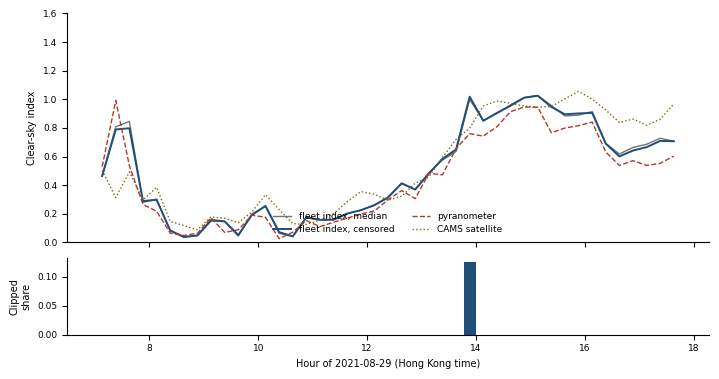

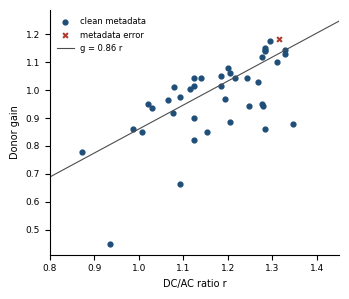

In [8]:
import matplotlib.pyplot as plt
from pvcold import io_hkust as io
A._style()
ref = 'SQ Apartment25-36'                       # validation event with the most donors in 2021
a = val_arrays[ref]; r = val_res[ref]
dev = a['window'] & np.asarray(a['t'] < pd.Timestamp(C.FIRST_TEST_DAY)) & (a['gt'] > 0.1)
kc = pd.Series(r['k_cens'], index=a['t'])[dev]; cc = pd.Series(r['c'], index=a['t'])[dev]
score = kc.groupby(kc.index.normalize()).std() * (cc.groupby(cc.index.normalize()).max() > 0.1)
DAY = score.idxmax()
ghi, _ = io.read_weather('ghi')
g1 = ghi[(ghi.time >= DAY) & (ghi.time < DAY + pd.Timedelta(days=1))].set_index('time')['value']
cams = io.read_cams(C.CAMS_HKUST)
cams.index = cams.index.tz_convert(C.TZ).tz_localize(None)
cd = cams.loc[DAY: DAY + pd.Timedelta(hours=23, minutes=59), 'GHI']
slots = a['t'][(a['t'] >= DAY) & (a['t'] < DAY + pd.Timedelta(days=1))]
gcs = p['geometry15'].loc[slots, 'G_cs']
k_sensor = g1.resample('15min').mean().reindex(slots) / gcs
k_cams = cd.resample('15min').mean().reindex(slots) / gcs
hrs = (slots.hour + slots.minute / 60 + 8 / 60)
sel = (a['t'] >= DAY) & (a['t'] < DAY + pd.Timedelta(days=1)) & (a['gt'] > 0.1)
day_ok = (gcs > 100).to_numpy(); hrs = hrs[day_ok]; k_sensor = k_sensor[day_ok]; k_cams = k_cams[day_ok]
f3, ax = plt.subplots(2, 1, figsize=(7.2, 3.8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax[0].plot(hrs, r['k_med'][sel], color='0.45', lw=1.0, label='fleet index, median')
ax[0].plot(hrs, r['k_cens'][sel], color='#1f4e79', lw=1.4, label='fleet index, censored')
ax[0].plot(hrs, k_sensor, color='#b03a2e', lw=1.0, ls='--', label='pyranometer')
ax[0].plot(hrs, k_cams, color='#7d6608', lw=1.0, ls=':', label='CAMS satellite')
ax[0].set_ylabel('Clear-sky index'); ax[0].set_ylim(0, 1.6); ax[0].legend(frameon=False, ncol=2, loc='lower center')
ax[1].bar(hrs, r['c'][sel], width=0.22, color='#1f4e79'); ax[1].set_ylabel('Clipped\nshare')
ax[1].set_xlabel(f'Hour of {DAY.date()} (Hong Kong time)'); f3.tight_layout()
last = E[E.set == 'scored'].sort_values('start').event.iloc[-1]
gl = gains[gains.event == last].set_index('donor')
ok = U.loc[gl.index, 'in_prior_test'].astype(bool)
rr = U.loc[gl.index, 'DC_AC']
beta = pri.set_index('event').loc[last, 'beta_G1']
f4, ax4 = plt.subplots(figsize=(3.5, 3.0))
ax4.scatter(rr[ok], gl.gain[ok], s=12, color='#1f4e79', label='clean metadata')
ax4.scatter(rr[~ok], gl.gain[~ok], s=12, marker='x', color='#b03a2e', label='metadata error')
xs = np.linspace(0.8, 1.45, 10); ax4.plot(xs, beta * xs, color='0.3', lw=0.8, label=f'g = {beta:.2f} r')
ax4.set_xlim(0.8, 1.45); ax4.set_xlabel('DC/AC ratio r'); ax4.set_ylabel('Donor gain'); ax4.legend(frameon=False, fontsize=6)
f4.tight_layout()
print('Fig. 3 day:', DAY.date(), '| Fig. 4 donor set of', last, '| corr(r, gain), clean donors: %.3f' % np.corrcoef(rr[ok], gl.gain[ok])[0, 1])

## Outputs (all-or-nothing)

In [9]:
summary = {'notebook': 'NB3_index_gains_prior', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
           'frozen1_written': time.strftime('%Y-%m-%d %H:%M:%S'),
           'k_min': K_MIN, 'estimator': ESTIMATOR, 'prior': PRIOR, 'frozen1_sha256': FROZEN1_HASH,
           'validation_nrmse0_by_kmin': tab.round(6).to_dict(), 'validation_nrmse0_by_estimator': med.round(6).to_dict(),
           'censored_wins': int((piv.cens_minus_med < 0).sum()),
           'validation_prior_median_abs_err': perr['abs_err'].round(6).to_dict(),
           'validation_prior_median_nrmse0': perr['nrmse0_prior'].round(6).to_dict(),
           'drift_boundary_fleet': bd_fleet, 'drift_boundary_cams': bd_cams,
           'scored_by_period': per[per.set == 'scored'].sensor_period.value_counts().to_dict(),
           'w0_days_median_scored': float(pri.loc[pri.set == 'scored', 'w0_days'].median()),
           'fig3_day': str(DAY.date()), 'fig4_event': last}
tables = {'validation_kmin': vk, 'validation_estimator': ve, 'validation_priors': vp, 'event_periods': per,
          'gains': gains, 'priors': pri}
pq = {k: v.reset_index(names='time') for k, v in idx.items()}
out = A.write_outputs('nb3_index', tables, summary, {'fig3_index_day': f3, 'fig4_gain_dcac': f4}, parquet=pq,
                      texts={'frozen_config_part1.yaml': FROZEN1_TEXT})
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb3_index | ['c.parquet', 'event_periods.csv', 'figures', 'frozen_config_part1.yaml', 'gains.csv', 'k_cens.parquet', 'k_med.parquet', 'n.parquet', 'priors.csv', 'sigma.parquet', 'summary.json', 'validation_estimator.csv', 'validation_kmin.csv', 'validation_priors.csv']
